# CS-430 Assignment 3
## Nikola Mrdak

In [20]:
#Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from numpy.random import logistic
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import classification_report

## Part 1 – Understand the Classification Problem (15 points)
### 1. Explore the dataset (7 points)
- Load the CSV. Display five rows, the data shape, the column names, and missing-value counts.
- Identify one numerical and one categorical feature.
- Answer: Why must past_due_rent be excluded from the input features?

In [2]:
url = '/content/drive/MyDrive/Colab Notebooks/Assignment3/SLCM_rent_arrears_student_clean.csv'
data = pd.read_csv(url)
data.head(5)

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


In [3]:
print(f'Data shape is {data.shape[0]} rows by {data.shape[1]} columns.')
print(f'~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(f'Column Names: {data.columns}')
print(f'~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(f'Missing Values:')
print(f'~~~~~~~~~~~~~~~')
print(f'{data.isnull().sum().sort_values(ascending = False)}')
print(f'~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')

Data shape is 1754 rows by 14 columns.
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Column Names: Index(['record_id', 'adults_in_household', 'children_in_household',
       'household_has_65plus', 'monthly_household_income', 'income_sources',
       'employment_status', 'has_housing_voucher', 'eviction_in_progress',
       'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter',
       'monthly_rent', 'past_due_rent'],
      dtype='object')
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Missing Values:
~~~~~~~~~~~~~~~
monthly_household_income      108
main_reason_behind_on_rent     16
monthly_rent                    8
behind_on_utilities             7
eviction_in_progress            1
record_id                       0
income_sources                  0
household_has_65plus            0
children_in_household           0
adults_in_household             0
employment_status               0
has_housing_voucher             0
inta

In [4]:
# 'monthly_household_income' and 'behind_on_utilities' dtypes
print(f'monthly_household_income dtype: {data["monthly_household_income"].dtype}')
print(f'behind_on_utilities dtype: {data["behind_on_utilities"].dtype}')

monthly_household_income dtype: float64
behind_on_utilities dtype: object


One categorical variable in this dataset is 'behind_on_utilities' and one numerical variable is 'monthly_household_income'. 'past_due_rent' must not be included in imput features because it is directly used in calculating the target variable - whether past due rent is above or below $3,000.

### 2. Create the target (8 points)
- Create high_arrears: 1 if past_due_rent is at least $3,000, otherwise 0.
- Show class counts and one bar chart of high_arrears.
- Answer: Which class is larger? Why might accuracy alone be misleading?


In [5]:
# Create high_arrears: 1 if past_due_rent is at least $3,000, otherwise 0.

data['high_arrears'] = np.where(data['past_due_rent'] >= 3000, 1, 0)
print(data['high_arrears'].dtype)
data.head()


int64


,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent,high_arrears
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0,1
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0,1
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0,1
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0,0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5,0


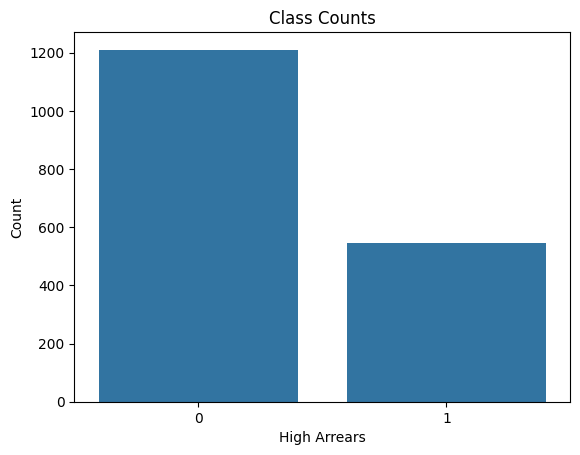

In [6]:
#Class counts
sns.countplot(x='high_arrears', data=data)
plt.title('Class Counts')
plt.xlabel('High Arrears')
plt.ylabel('Count')
plt.show()

In [7]:
data['high_arrears'].value_counts()

,count
high_arrears,
0,1210
1,544


The class of less than three thousand dollars is the larger class (0). This may affect the accuracy score by decreasing recall. If the classes are unbalanced, the model may struggle to correctly predict actual cases that are more than three thousand dollars in past due rent.

## Part 2 – Prepare the Data (25 points)
### 3. Select features and split (10 points)
- Create X by dropping record_id, past_due_rent, and high_arrears. Set y = high_arrears.
- Split the data once into training and testing sets.
- Answer: Why do we keep a separate test set?

In [8]:
X = data.drop(['record_id', 'past_due_rent', 'high_arrears'], axis=1)
y = data['high_arrears']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

It is vital to keep a separate test set so that the model can predict on unfamiliar data points.

### 4. Build one reusable preprocessor (15 points)
- Identify numerical and categorical columns with select_dtypes.
- Numerical: fill missing values using median and apply StandardScaler.
- Categorical: fill missing values using most_frequent and apply OneHotEncoder(handle_unknown="ignore").
- Combine with ColumnTransformer. You may reuse the class example.
- Answer: Why is scaling helpful for KNN and SVC?


In [9]:
#Splitting categoricals and numericals
categorical_features = X_train.select_dtypes(include=['object']).columns
numerical_features = X_train.select_dtypes(include=['int64', 'float64']).columns
print('Categorical Features')
print(f'~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(X_train[categorical_features].dtypes)
print(f' ')
print('Numerical Features')
print(f'~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(X_train[numerical_features].dtypes)

Categorical Features
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
household_has_65plus          object
income_sources                object
employment_status             object
has_housing_voucher           object
eviction_in_progress          object
behind_on_utilities           object
main_reason_behind_on_rent    object
intake_quarter                object
dtype: object
 
Numerical Features
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
adults_in_household           int64
children_in_household         int64
monthly_household_income    float64
monthly_rent                float64
dtype: object


In [10]:
print('Numerical Features')
print(f'~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(X_train[numerical_features].dtypes)
print(f' ')
print('Categorical Features')
print(f'~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(X_train[categorical_features].dtypes)

Numerical Features
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
adults_in_household           int64
children_in_household         int64
monthly_household_income    float64
monthly_rent                float64
dtype: object
 
Categorical Features
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
household_has_65plus          object
income_sources                object
employment_status             object
has_housing_voucher           object
eviction_in_progress          object
behind_on_utilities           object
main_reason_behind_on_rent    object
intake_quarter                object
dtype: object


In [11]:
#fill missing values using median and apply StandardScaler.
#Categorical: fill missing values using most_frequent and apply OneHotEncoder(handle_unknown="ignore").

preprocessor = ColumnTransformer(
    transformers=[
        ('numericals', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numerical_features),
        ('categoricals', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ])


Scaling is important for KNN and SVC because these models rely on distance-based methods to make predictions. KNN classifies data points based on Euclidean Distance and SVC relies on a decision boundary. Without scaling, large datapoints, like income, may skew these models to yield unaccurate predictions.

## Part 3 – Train and Compare Five Models (45 points)
### 5. Train the five classifiers (20 points)
- Build five pipelines with the same preprocessor, the same training set, and these models:
- Logistic Regression: LogisticRegression(max_iter=1000)
- KNN: KNeighborsClassifier(n_neighbors=5)
- Decision Tree: DecisionTreeClassifier(max_depth=5, random_state=42)
- Random Forest: RandomForestClassifier(n_estimators=100, random_state=42)
- Support Vector Classifier: SVC()
- Fit each pipeline and report test accuracy, recall, and F1 for class 1. Use a short, repeated code pattern; you do not
need a loop or custom functions.


In [12]:
#Logistic Regression with preprocessor fit and pred

logistic = LogisticRegression(max_iter=1000)
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                       ('classifier', logistic)])
pipeline.fit(X_train, y_train)
logistic_y_pred = pipeline.predict(X_test)

logistic_accuracy = accuracy_score(y_test, logistic_y_pred)
print(f'Accuracy: {logistic_accuracy}')
logistic_recall = recall_score(y_test, logistic_y_pred)
print(f'Recall: {logistic_recall}')
logistic_f1 = f1_score(y_test, logistic_y_pred)
print(f'F1: {logistic_f1}')

Accuracy: 0.7492877492877493
Recall: 0.41935483870967744
F1: 0.46987951807228917


In [13]:
#KNeighborsClassifier with n = 5

KNN = KNeighborsClassifier(n_neighbors=5)
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                       ('classifier', KNN)])
pipeline.fit(X_train, y_train)
KNN_y_pred = pipeline.predict(X_test)

KNN_accuracy = accuracy_score(y_test, KNN_y_pred)
print(f'Accuracy: {KNN_accuracy}')
KNN_recall = recall_score(y_test, KNN_y_pred)
print(f'Recall: {KNN_recall}')
KNN_f1 = f1_score(y_test, KNN_y_pred)
print(f'F1: {KNN_f1}')


Accuracy: 0.7407407407407407
Recall: 0.5268817204301075
F1: 0.5185185185185185


In [14]:
#Decision Tree Classifier

decision_tree = DecisionTreeClassifier(max_depth=5, random_state=42)
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                       ('classifier', decision_tree)])
pipeline.fit(X_train, y_train)
tree_y_pred = pipeline.predict(X_test)

decision_tree_accuracy = accuracy_score(y_test, tree_y_pred)
print(f'Accuracy: {decision_tree_accuracy}')
decision_tree_recall = recall_score(y_test, tree_y_pred)
print(f'Recall: {decision_tree_recall}')
decision_tree_f1 = f1_score(y_test, tree_y_pred)
print(f'F1: {decision_tree_f1}')

Accuracy: 0.7378917378917379
Recall: 0.24731182795698925
F1: 0.3333333333333333


In [15]:
#Random Forest Classifier

random_forest = RandomForestClassifier(n_estimators=100, random_state=42)
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                       ('classifier', random_forest)])
pipeline.fit(X_train, y_train)
forest_y_pred = pipeline.predict(X_test)

random_forest_accuracy = accuracy_score(y_test, forest_y_pred)
print(f'Accuracy: {random_forest_accuracy}')
random_forest_recall = recall_score(y_test, forest_y_pred)
print(f'Recall: {random_forest_recall}')
random_forest_f1 = f1_score(y_test, forest_y_pred)
print(f'F1: {random_forest_f1}')

Accuracy: 0.7578347578347578
Recall: 0.41935483870967744
F1: 0.4785276073619632


In [16]:
#SVC

svc = SVC()
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                       ('classifier', svc)])
pipeline.fit(X_train, y_train)
SVC_y_pred = pipeline.predict(X_test)

svc_accuracy = accuracy_score(y_test, SVC_y_pred)
print(f'Accuracy: {svc_accuracy}')
svc_recall = recall_score(y_test, SVC_y_pred)
print(f'Recall: {svc_recall}')
svc_f1 = f1_score(y_test, SVC_y_pred)
print(f'F1: {svc_f1}')

Accuracy: 0.7578347578347578
Recall: 0.3763440860215054
F1: 0.45161290322580644


### 6. Compare the models (10 points)
- Put the test results in one table with columns: Model, Accuracy, Recall, F1.
- Create one confusion matrix for the model with the highest test F1.
- Answer: Which model catches the highest proportion of high-arrears households? What does a missed case mean for
SLCM?

In [17]:
#Dataframe with all five models' accuracy, recall, and f1 scores
comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'SVC'],
    'Accuracy': [logistic_accuracy, KNN_accuracy, decision_tree_accuracy, random_forest_accuracy, svc_accuracy],
    'Recall': [logistic_recall, KNN_recall, decision_tree_recall, random_forest_recall, svc_recall],
    'F1': [logistic_f1, KNN_f1, decision_tree_f1, random_forest_f1, svc_f1]
})

comparison_df

,Model,Accuracy,Recall,F1
0,Logistic Regression,0.749288,0.419355,0.469880
1,KNN,0.740741,0.526882,0.518519
2,Decision Tree,0.737892,0.247312,0.333333
3,Random Forest,0.757835,0.419355,0.478528
4,SVC,0.757835,0.376344,0.451613


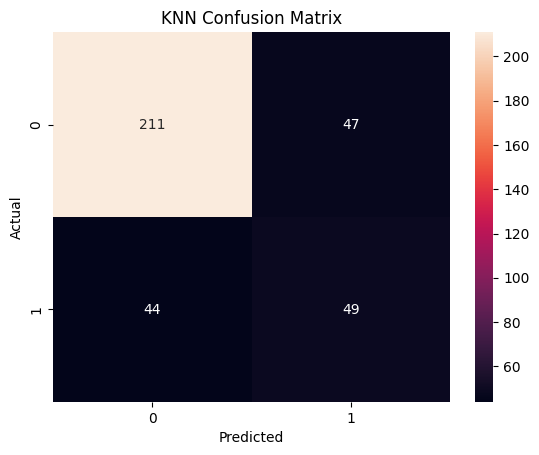

In [18]:
#Highest F1: KNN
#KNN Confusion Matrix
sns.heatmap(confusion_matrix(y_test, KNN_y_pred), annot=True, fmt='g')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('KNN Confusion Matrix')
plt.show()


In [19]:
KNN_recall

0.5268817204301075

The KNN model catches the highest number of actual high-arrers households as it yields the highest recall score. This score measures the actual values the model correctly predicts. A high recall is important for SLCM because missing a true case of vulernability in a household means they may go without assistance SCLM is able to provide otherwise.

### 7. Try a small GridSearchCV (15 points)
- Tune only two models on the training set with cv=3 and scoring="f1".
- For KNN, try n_neighbors = [3, 5, 7].
- For Random Forest, try max_depth = [3, 5, None] (keep n_estimators=100).
- Print best_params_ and best_score_ for each search. No extra charts or second search are needed.
- Answer: Which has the higher best cross-validation F1? Why is GridSearchCV fitted on training data only?

In [29]:
KNN_2 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])


KNN_2_grid = {"classifier__n_neighbors": [3, 5, 7]}

KNN_2_search = GridSearchCV(KNN_2, KNN_2_grid, cv=3, scoring="f1")
KNN_2_search.fit(X_train, y_train)

print("Best KNN parameters:", KNN_2_search.best_params_)
print("KNN CV f1:", round(KNN_2_search.best_score_, 3))

Best KNN parameters: {'classifier__n_neighbors': 7}
KNN CV f1: 0.447


In [26]:
Forest2 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# We must prefix the parameters with 'classifier__' to target the estimator inside the Pipeline
Forest2_grid = {"classifier__max_depth": [3, 5, None]}

Forest2_search = GridSearchCV(Forest2, Forest2_grid, cv=3, scoring="f1")
Forest2_search.fit(X_train, y_train)

print("Best RF parameters:", Forest2_search.best_params_)
print("RF CV f1:", round(Forest2_search.best_score_, 3))

Best RF parameters: {'classifier__max_depth': None}
RF CV f1: 0.467


KNN yielded an f1 score of 0.447 and Random Forest yieled 0.467. Gridsearch is only fitted to trainig data to avoid data leakage.

## Part 4 – Explain the Results (15 points)
### 8. Interpret your comparison (8 points)
- In 4–5 sentences, identify the most promising model based on your results. Explain your choice using F1 and recall, not
accuracy alone.
- Did a more complex model necessarily perform better? What types of errors should SLCM pay attention to?

Based on the test results, the K-Nearest Neighbors model is the most promising model because it achieved both the highest F1-score (0.519) and the highest recall (0.527) on the test set. While the Random Forest and Support Vector Classifier models yielded slightly higher test accuracies (0.758), accuracy alone is misleading due to class imbalance, and their F1 and recall scores are notably lower. A more complex model, like Random Forest, did not necessarily perform better here as the simpler KNN model captured more true high-arrears households. For SLCM, type two errors, predicting a household is not in high arrears when they actually are, is a critical error they must pay attention to, as missing these cases means vulnerable families may go without the vital assistance they need.

### 9. Recommendation to SLCM (7 points)
- Write 4–5 sentences for a non-technical SLCM audience: what you tried to predict, how well the selected model
performed, one practical insight, and one limitation.
- State that a prediction is not proof of cause and must not be used alone to decide eligibility for assistance.

For this project, the goal was to predict whether a household would accumulate high rent arrears (past due rent of $3,000 or more) using factors like household income, size, and utility bill status. Our selected K-Nearest Neighbors (KNN) model performed fair, correctly identifying approximately 52.7% of the households that actually reached high arrears (recall) while maintaining a balanced overall F1-score of 0.519. From the analysis, it can be infered that household indicators like being behind on utility bills can serve as strong early warnings for escalating rent debt. However, a key limitation of the model is that it still misses about 47.3% of high-arrears cases (false negatives) and a correlation does not prove any patterns concretely.